# 01 · Exploratory data analysis and data quality

This notebook describes the FAERS data **after** the pipeline of Phase 1
(`make load` and `make transform`). It answers three questions before any
signal detection method is applied:

1. How much data is there, and what did deduplication and cleaning remove?
2. Who reports, about whom, and with what quality (missing values)?
3. How sparse is the drug-event table that every method will use?

All queries run directly on `data/faers_warehouse.duckdb`. Figures are also
saved to `reports/figures/` for the final report.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from faers import plotting as P

DB = Path("../data/faers_warehouse.duckdb")
FIGURES = Path("../reports/figures")
con = duckdb.connect(str(DB), read_only=True)


def sql(query):
    """Run a query and return a pandas DataFrame."""
    return con.execute(query).df()


pd.options.display.float_format = "{:,.1f}".format

P.apply_style()


def save(fig, name):
    P.save(fig, name, folder=FIGURES)

## 1. How much data, and what the pipeline removed

In [2]:
quarters = sql("""
    SELECT quarter, SUM(rows_loaded) FILTER (WHERE table_name = 'demo') AS reports,
           SUM(rows_rejected) AS rejected_lines
    FROM load_log GROUP BY quarter ORDER BY quarter
""")
print(f"Quarters loaded: {len(quarters)} ({quarters.quarter.iloc[0]} to {quarters.quarter.iloc[-1]})")
print(f"Lines rejected while loading: {int(quarters.rejected_lines.sum())}")

funnel = sql("""
    SELECT 'Report rows in the raw files' AS step, COUNT(*) AS n FROM raw_demo
    UNION ALL SELECT 'Distinct cases (caseid)', COUNT(DISTINCT caseid) FROM raw_demo
    UNION ALL SELECT 'Cases after deduplication and deletions', COUNT(*) FROM demo_dedup
    UNION ALL SELECT 'Cases with a primary suspect drug and a clinical reaction',
                     COUNT(DISTINCT primaryid) FROM report_drug_event
""")
funnel["% of raw rows"] = 100 * funnel.n / funnel.n.iloc[0]
funnel.style.format({"n": "{:,.0f}", "% of raw rows": "{:.1f}"}).hide(axis="index")

Quarters loaded: 48 (2014q3 to 2026q2)
Lines rejected while loading: 5


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

step,n,% of raw rows
Report rows in the raw files,"19,001,338",100.0
Distinct cases (caseid),"16,265,596",85.6
Cases after deduplication and deletions,"16,172,840",85.1
Cases with a primary suspect drug and a clinical reaction,"14,208,658",74.8


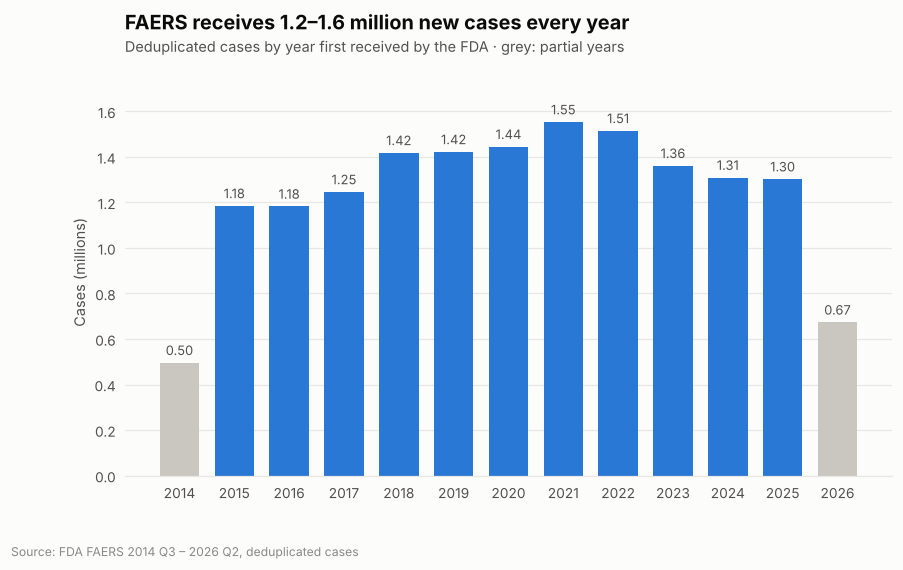

In [3]:
# New cases per year, by the date the FDA first received them (init_fda_dt).
per_year = sql("""
    SELECT YEAR(init_fda_dt) AS year, COUNT(*) AS cases
    FROM demo_dedup WHERE init_fda_dt IS NOT NULL
    GROUP BY 1 ORDER BY 1
""")
per_year = per_year[per_year.year >= 2014]
partial = per_year.year.isin([2014, 2026])

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(per_year.year, per_year.cases / 1e6, width=0.72,
              color=[P.NEUTRAL if p else P.ACCENT for p in partial])
P.label_bars(ax, bars, fmt="{:.2f}")
ax.set_xticks(per_year.year)
ax.set_ylim(0, per_year.cases.max() / 1e6 * 1.15)
ax.set_ylabel("Cases (millions)")
P.headline(ax, "FAERS receives 1.2–1.6 million new cases every year",
           "Deduplicated cases by year first received by the FDA · grey: partial years")
P.source_note(fig)
save(fig, "cases_per_year")

Cases first received before 2014 still appear: they are older cases whose
follow-up versions were published inside the window. The first and last years
are incomplete (the window starts in 2014 Q3 and ends in 2026 Q2).

## 2. Who reports, and about whom

In [4]:
def share(query, label):
    df = sql(query)
    df["%"] = 100 * df.n / df.n.sum()
    return df.rename(columns={"value": label})

report_type = share("""
    SELECT CASE rept_cod WHEN 'EXP' THEN 'Expedited (15-day)' WHEN 'PER' THEN 'Periodic'
                         WHEN 'DIR' THEN 'Direct (non-manufacturer)' WHEN '30DAY' THEN '30-day'
                         WHEN '5DAY' THEN '5-day' ELSE COALESCE(rept_cod, 'Missing') END
           AS value, COUNT(*) AS n
    FROM demo_dedup GROUP BY 1 ORDER BY 2 DESC""", "Report type")
reporter = share("""
    SELECT CASE occp_cod WHEN 'MD' THEN 'Physician' WHEN 'PH' THEN 'Pharmacist'
                         WHEN 'OT' THEN 'Other health professional' WHEN 'HP' THEN 'Health professional'
                         WHEN 'LW' THEN 'Lawyer' WHEN 'CN' THEN 'Consumer' ELSE 'Missing' END
           AS value, COUNT(*) AS n
    FROM demo_dedup GROUP BY 1 ORDER BY 2 DESC""", "Reporter")
display(report_type.style.format({"n": "{:,.0f}", "%": "{:.1f}"}).hide(axis="index"))
display(reporter.style.format({"n": "{:,.0f}", "%": "{:.1f}"}).hide(axis="index"))

Report type,n,%
Expedited (15-day),"8,036,366",49.7
Periodic,"7,222,777",44.7
Direct (non-manufacturer),"799,429",4.9
30-day,"108,129",0.7
5-day,"6,131",0.0
Missing,8,0.0


Reporter,n,%
Consumer,"7,183,897",44.4
Physician,"3,452,787",21.3
Health professional,"1,854,370",11.5
Other health professional,"1,244,986",7.7
Pharmacist,"1,049,441",6.5
Missing,"954,926",5.9
Lawyer,"432,433",2.7


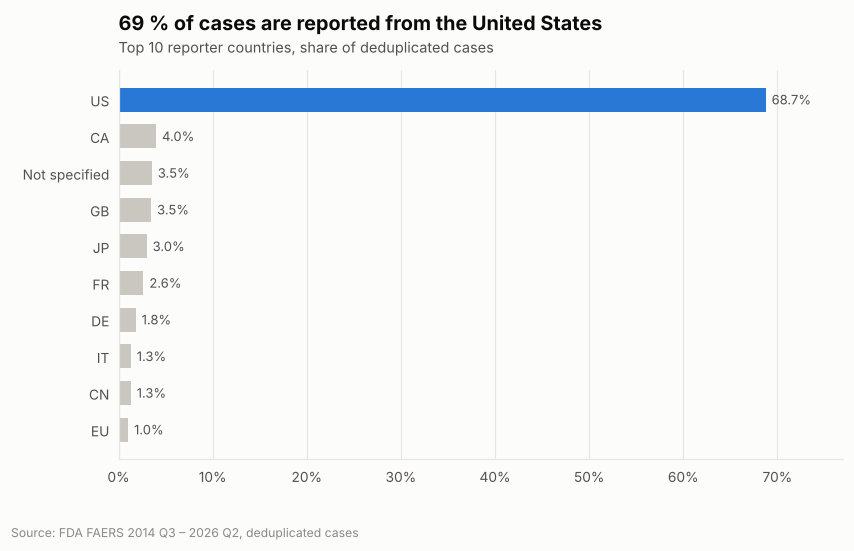

In [5]:
countries = sql("""
    SELECT CASE WHEN reporter_country IS NULL OR reporter_country = 'COUNTRY NOT SPECIFIED'
                THEN 'Not specified' ELSE reporter_country END AS country, COUNT(*) AS n
    FROM demo_dedup GROUP BY 1 ORDER BY 2 DESC LIMIT 10
""")
total_cases = sql("SELECT COUNT(*) AS n FROM demo_dedup").n[0]
countries["%"] = 100 * countries.n / total_cases

fig, ax = plt.subplots(figsize=(8.5, 4.6))
colors = [P.ACCENT if c == "US" else P.NEUTRAL for c in countries.country]
bars = ax.barh(countries.country[::-1], countries["%"][::-1], color=colors[::-1], height=0.66)
P.horizontal_bars(ax)
P.label_bars(ax, bars, horizontal=True, fmt="{:.1f}%")
P.percent(ax, axis="x")
ax.set_xlim(0, countries["%"].max() * 1.12)
P.headline(ax, f"{countries['%'].iloc[0]:.0f} % of cases are reported from the United States",
           "Top 10 reporter countries, share of deduplicated cases")
P.source_note(fig)
save(fig, "reporter_countries")

Cases with a usable age: 56.8%
Median age: 59 years


sex
F         51.6
M         34.5
Missing   13.8
UNK        0.1
P          0.0
I          0.0
T          0.0


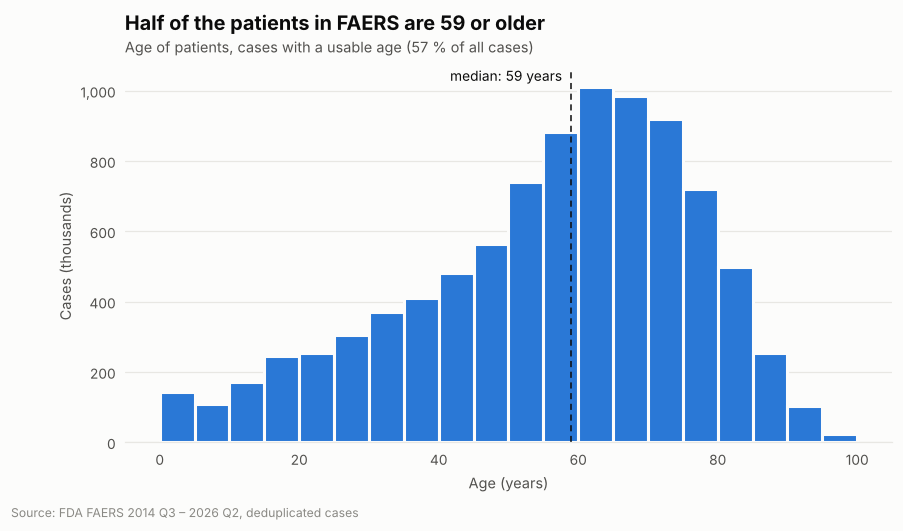

In [6]:
# Age in years: FAERS stores a number plus a unit (age_cod).
ages = sql("""
    SELECT sex, age * CASE age_cod WHEN 'YR' THEN 1 WHEN 'DEC' THEN 10 WHEN 'MON' THEN 1/12
                                    WHEN 'WK' THEN 1/52 WHEN 'DY' THEN 1/365 WHEN 'HR' THEN 1/8760 END
               AS age_years
    FROM demo_dedup
""")
valid = ages.age_years.between(0, 110)
median_age = ages.age_years[valid].median()
print(f"Cases with a usable age: {100 * valid.mean():.1f}%")
print(f"Median age: {median_age:.0f} years")
print(ages.sex.fillna("Missing").value_counts(normalize=True).mul(100).round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.hist(ages.age_years[valid], bins=range(0, 105, 5), weights=[1e-3] * valid.sum(),
        color=P.ACCENT, edgecolor=P.SURFACE, linewidth=2)
ax.axvline(median_age, color=P.INK, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate(f"median: {median_age:.0f} years", (median_age, ax.get_ylim()[1] * 0.97),
            xytext=(-6, 0), textcoords="offset points", fontsize=9, color=P.INK, ha="right")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Cases (thousands)")
P.thousands(ax)
P.headline(ax, f"Half of the patients in FAERS are {median_age:.0f} or older",
           f"Age of patients, cases with a usable age ({100 * valid.mean():.0f} % of all cases)")
P.source_note(fig)
save(fig, "age_distribution")

In [7]:
# Missing values in the fields we may use later.
missing = sql("""
    SELECT
        100 * AVG(CASE WHEN age IS NULL THEN 1 ELSE 0 END)              AS age,
        100 * AVG(CASE WHEN sex IS NULL OR sex = 'UNK' THEN 1 ELSE 0 END) AS sex,
        100 * AVG(CASE WHEN occp_cod IS NULL THEN 1 ELSE 0 END)         AS reporter,
        100 * AVG(CASE WHEN reporter_country IS NULL
                       OR reporter_country = 'COUNTRY NOT SPECIFIED' THEN 1 ELSE 0 END) AS country,
        100 * AVG(CASE WHEN init_fda_dt IS NULL THEN 1 ELSE 0 END)      AS init_fda_dt
    FROM demo_dedup
""").T.rename(columns={0: "% missing"})
missing

,% missing
age,43.2
sex,13.9
reporter,5.9
country,3.5
init_fda_dt,0.0


## 3. Drugs

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Primary suspect drug names: 6,536 -> 5,424 after normalisation
Reports with more than one primary suspect drug: 0.00%


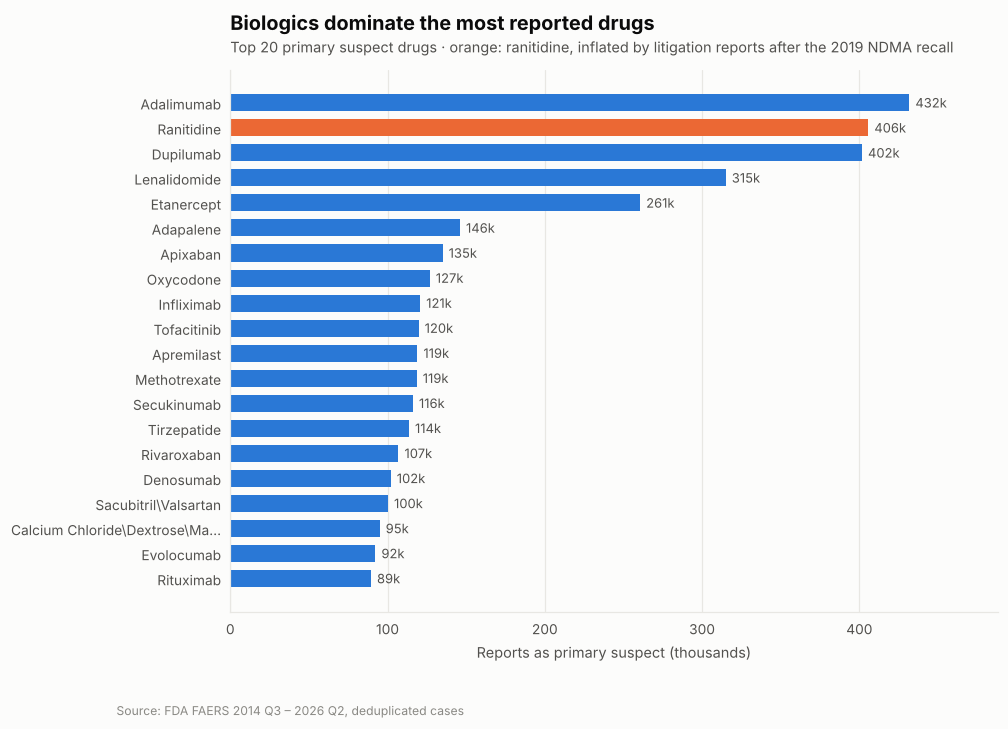

In [8]:
drugs = sql("""
    SELECT COUNT(DISTINCT d.drug_name) AS names_before, COUNT(DISTINCT m.drug) AS drugs_after
    FROM drug_clean AS d JOIN drug_name_map AS m USING (drug_name)
    WHERE d.role_cod = 'PS'
""")
ps_per_report = sql("""
    SELECT n_ps, COUNT(*) AS reports FROM (
        SELECT primaryid, COUNT(DISTINCT drug) AS n_ps FROM report_drug_event GROUP BY 1
    ) GROUP BY 1 ORDER BY 1
""")
print(f"Primary suspect drug names: {drugs.names_before[0]:,} -> {drugs.drugs_after[0]:,} after normalisation")
print(f"Reports with more than one primary suspect drug: "
      f"{100 * ps_per_report.reports[ps_per_report.n_ps > 1].sum() / ps_per_report.reports.sum():.2f}%")

top_drugs = sql("""
    SELECT DISTINCT drug, n_drug FROM drug_event_counts ORDER BY n_drug DESC LIMIT 20
""")
short = top_drugs.drug.where(top_drugs.drug.str.len() <= 30, top_drugs.drug.str[:28] + "…")
short = short.str.title()
fig, ax = plt.subplots(figsize=(9, 6.4))
colors = [P.HIGHLIGHT if d == "RANITIDINE" else P.ACCENT for d in top_drugs.drug]
bars = ax.barh(short[::-1], top_drugs.n_drug[::-1] / 1e3, color=colors[::-1], height=0.68)
P.horizontal_bars(ax)
P.label_bars(ax, bars, horizontal=True, fmt="{:,.0f}k")
ax.set_xlim(0, top_drugs.n_drug.max() / 1e3 * 1.13)
ax.set_xlabel("Reports as primary suspect (thousands)")
P.headline(ax, "Biologics dominate the most reported drugs",
           "Top 20 primary suspect drugs · orange: ranitidine, inflated by litigation reports after the 2019 NDMA recall")
P.source_note(fig)
save(fig, "top_drugs")

## 4. Reactions

Reaction rows that are not clinical: 15.0% (excluded from counts)


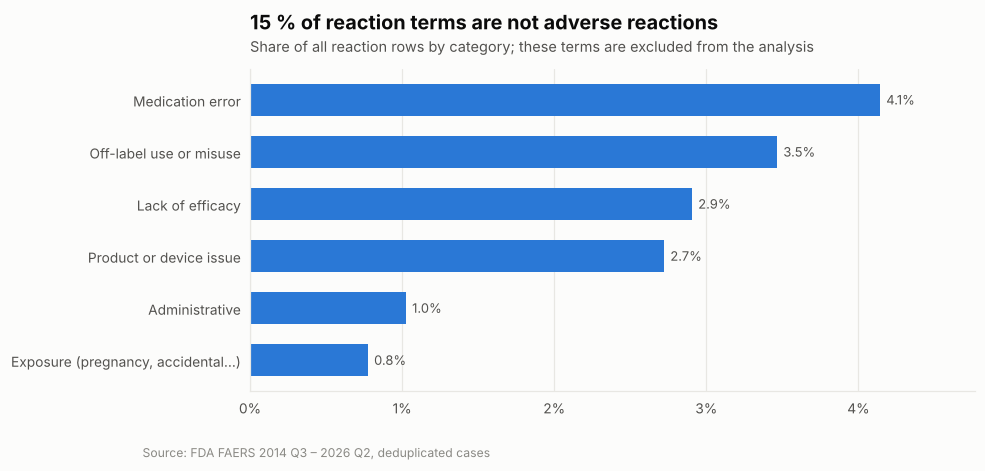

In [9]:
categories = sql("""
    SELECT c.category, COUNT(*) AS n
    FROM reac_clean AS r JOIN pt_class AS c USING (pt)
    GROUP BY 1 ORDER BY 2 DESC
""")
categories["%"] = 100 * categories.n / categories.n.sum()
non_clinical = categories[categories.category != "clinical"]
print(f"Reaction rows that are not clinical: {non_clinical['%'].sum():.1f}% (excluded from counts)")

NAMES = {"medication_error": "Medication error", "off_label_or_misuse": "Off-label use or misuse",
         "lack_of_efficacy": "Lack of efficacy", "product_or_device_issue": "Product or device issue",
         "administrative": "Administrative", "exposure": "Exposure (pregnancy, accidental...)"}
fig, ax = plt.subplots(figsize=(8.5, 3.8))
labels = non_clinical.category.map(NAMES)
bars = ax.barh(labels[::-1], non_clinical["%"][::-1], color=P.ACCENT, height=0.62)
P.horizontal_bars(ax)
P.label_bars(ax, bars, horizontal=True, fmt="{:.1f}%")
P.percent(ax, axis="x")
ax.set_xlim(0, non_clinical["%"].max() * 1.15)
P.headline(ax, f"{non_clinical['%'].sum():.0f} % of reaction terms are not adverse reactions",
           "Share of all reaction rows by category; these terms are excluded from the analysis")
P.source_note(fig)
save(fig, "non_clinical_terms")

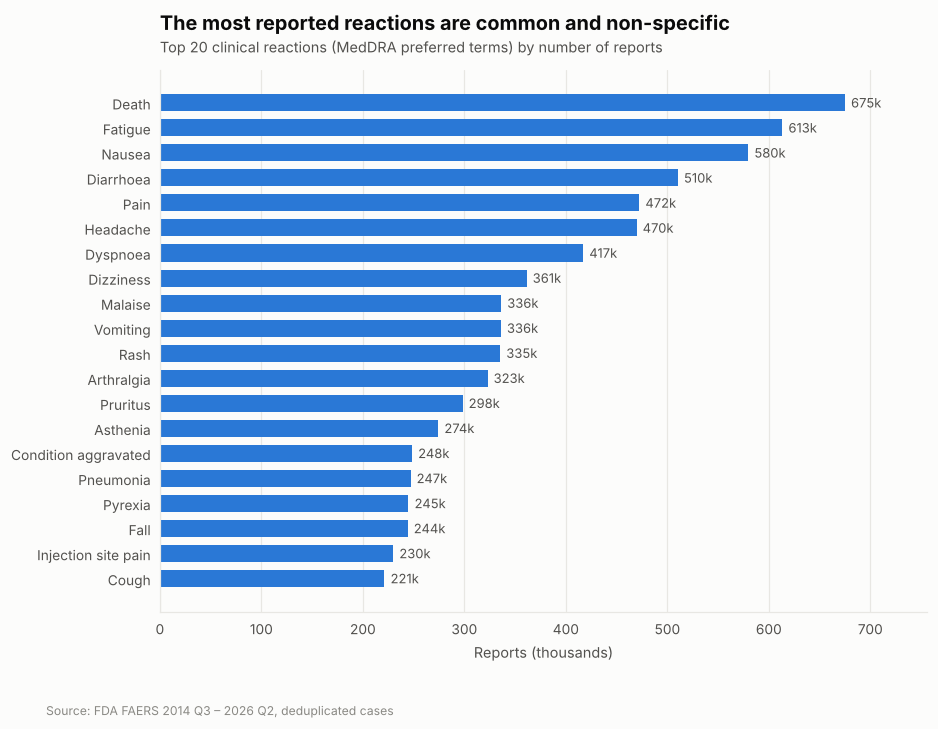

In [10]:
top_pts = sql("""
    SELECT DISTINCT pt, n_event FROM drug_event_counts ORDER BY n_event DESC LIMIT 20
""")
fig, ax = plt.subplots(figsize=(9, 6.4))
bars = ax.barh(top_pts.pt.str.capitalize()[::-1], top_pts.n_event[::-1] / 1e3,
               color=P.ACCENT, height=0.68)
P.horizontal_bars(ax)
P.label_bars(ax, bars, horizontal=True, fmt="{:,.0f}k")
ax.set_xlim(0, top_pts.n_event.max() / 1e3 * 1.12)
ax.set_xlabel("Reports (thousands)")
P.headline(ax, "The most reported reactions are common and non-specific",
           "Top 20 clinical reactions (MedDRA preferred terms) by number of reports")
P.source_note(fig)
save(fig, "top_reactions")

In [11]:
outcomes = sql("""
    SELECT CASE outc_cod WHEN 'DE' THEN 'Death' WHEN 'LT' THEN 'Life-threatening'
                         WHEN 'HO' THEN 'Hospitalisation' WHEN 'DS' THEN 'Disability'
                         WHEN 'CA' THEN 'Congenital anomaly' WHEN 'RI' THEN 'Required intervention'
                         WHEN 'OT' THEN 'Other serious' ELSE outc_cod END AS outcome,
           100 * COUNT(DISTINCT primaryid) / (SELECT COUNT(*) FROM demo_dedup) AS pct_cases
    FROM outc_clean GROUP BY 1 ORDER BY 2 DESC
""")
outcomes  # a case can have several outcomes, so the column does not add up to 100

,outcome,pct_cases
0,Other serious,37.9
1,Hospitalisation,20.0
2,Death,8.6
3,Life-threatening,2.6
4,Disability,1.6
5,Congenital anomaly,0.3
6,Required intervention,0.2


## 5. How sparse is the drug-event table?

Every method works on the 2x2 table of each drug-event pair. When the number
of reports with both the drug and the event (`a`) is very small, frequentist
ratios such as PRR and ROR are unstable; this is what Bayesian shrinkage
(BCPNN, EBGM) is designed for.

a_bin,pairs,%
1,"1,004,994",43.9
2,"340,343",14.9
3–4,"296,355",12.9
5–9,"261,422",11.4
10–99,"328,314",14.3
100+,"57,174",2.5


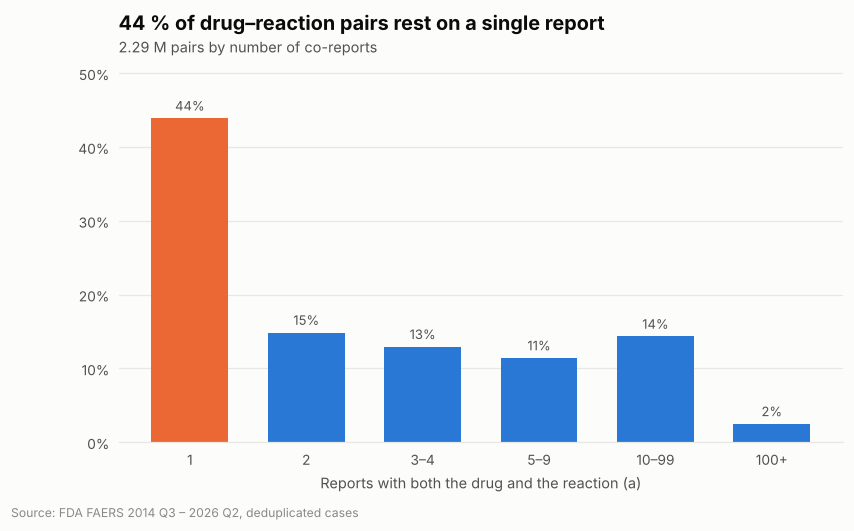

In [12]:
sparsity = sql("""
    SELECT CASE WHEN a = 1 THEN '1' WHEN a = 2 THEN '2' WHEN a <= 4 THEN '3–4'
                WHEN a <= 9 THEN '5–9' WHEN a <= 99 THEN '10–99' ELSE '100+' END AS a_bin,
           MIN(a) AS sort_key, COUNT(*) AS pairs
    FROM drug_event_counts GROUP BY 1 ORDER BY sort_key
""")
sparsity["%"] = 100 * sparsity.pairs / sparsity.pairs.sum()

fig, ax = plt.subplots(figsize=(8.5, 4.4))
colors = [P.HIGHLIGHT if b == "1" else P.ACCENT for b in sparsity.a_bin]
bars = ax.bar(sparsity.a_bin, sparsity["%"], color=colors, width=0.66)
P.label_bars(ax, bars, fmt="{:.0f}%")
P.percent(ax)
ax.set_ylim(0, sparsity["%"].max() * 1.15)
ax.set_xlabel("Reports with both the drug and the reaction (a)")
P.headline(ax, f"{sparsity['%'].iloc[0]:.0f} % of drug–reaction pairs rest on a single report",
           f"{sparsity.pairs.sum() / 1e6:.2f} M pairs by number of co-reports")
P.source_note(fig)
save(fig, "pair_sparsity")
sparsity.drop(columns="sort_key").style.format({"pairs": "{:,.0f}", "%": "{:.1f}"}).hide(axis="index")

## 6. Key findings

Full window: 48 quarters (2014 Q3 – 2026 Q2).

**Volume and cleaning**
- 19.0 M report rows become **16.2 M unique cases** after keeping the latest version of each case (−14.4 %) and removing the cases the FDA deleted. Only 5 lines in the whole raw data could not be parsed.
- 14.2 M cases (75 % of the raw rows) have a primary suspect drug and at least one clinical reaction: this is the universe of the benchmark.
- Every report has exactly **one** primary suspect drug, so drug-level counts are not inflated by multi-drug reports.
- 15 % of reaction rows are not adverse reactions (medication errors, off-label use, lack of efficacy, product or device complaints, exposures) and are excluded from the counts.

**Who reports**
- 44 % of cases come from **consumers** and only 21 % from physicians; 69 % come from the US.
- Age is missing in 43 % of cases and sex in 14 %, which limits any stratified analysis.
- **Stimulated reporting is visible:** ranitidine is the 2nd most reported drug, but 46 % of its reports were filed by **lawyers**, mostly in 2021–2022, and its top reactions are cancers. This follows the 2019–2020 NDMA recall and the litigation that came after it. It is a textbook example of notoriety bias, and a case study for Phase 5.

**Implications for the methods (Phase 3)**
- The drug-event table is very sparse: **44 % of pairs have a single co-report** (a = 1) and 59 % have a ≤ 2. Frequentist ratios (PRR, ROR) are unstable there, which is exactly what Bayesian shrinkage (BCPNN, EBGM) is designed to handle, and why a minimum-count rule (a ≥ 3) is usually added to PRR/ROR.
- Known signals are clearly detected by a plain PRR on the full window: levofloxacin – tendon rupture (98), semaglutide – optic ischaemic neuropathy (102), amiodarone – pulmonary fibrosis (61), montelukast – suicidal ideation (23). The interesting question for the benchmark is therefore **when** each method first flags them.
